In [10]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

n_samples = 1000

# Generate dummy data for 7 columns
loan_id = [f"LP{i:04d}" for i in range(1, n_samples + 1)]
age = np.random.randint(21, 65, size=n_samples)
income = np.random.randint(20000, 150000, size=n_samples)
loan_amount = np.random.randint(5000, 500000, size=n_samples)
credit_score = np.random.randint(300, 850, size=n_samples)
debt_to_income = np.round(np.random.uniform(0.1, 0.6, size=n_samples), 2)

# Simple logic to determine loan approval (1 = Approved, 0 = Rejected)
# Credit score and lower DTI ratio increase approval chances
approval_score = (credit_score / 850.0) * 0.6 + (1 - debt_to_income) * 0.4
loan_status = np.where(approval_score > 0.5, 'Approved', 'Rejected')

# Create DataFrame with exactly 7 columns
df_loans = pd.DataFrame({
    'Loan_ID': loan_id,
    'Age': age,
    'Income': income,
    'Loan_Amount': loan_amount,
    'Credit_Score': credit_score,
    'Debt_to_Income_Ratio': debt_to_income,
    'Loan_Status': loan_status
})

# Display dataset info and first few rows
print(f"Dataset shape: {df_loans.shape}")
print("\nLoan Status Distribution:")
print(df_loans['Loan_Status'].value_counts())
print("\nFirst 5 rows of the dataset:")
df_loans.head()

Dataset shape: (1000, 7)

Loan Status Distribution:
Loan_Status
Approved    904
Rejected     96
Name: count, dtype: int64

First 5 rows of the dataset:


,Loan_ID,Age,Income,Loan_Amount,Credit_Score,Debt_to_Income_Ratio,Loan_Status
0,LP0001,59,24018,52837,400,0.45,Approved
1,LP0002,49,31302,265550,307,0.57,Rejected
2,LP0003,35,87506,278680,499,0.35,Approved
3,LP0004,63,61157,33541,804,0.22,Approved
4,LP0005,28,74917,84083,386,0.12,Approved


### Balanced Dataset Generation
We will now generate a balanced dataset where the occurrences of `Approved` and `Rejected` are roughly equal (50% each).

In [15]:
import pandas as pd
import numpy as np

np.random.seed(42)
n_samples = 1000

loan_id = [f"LP{i:04d}" for i in range(1, n_samples + 1)]
age = np.random.randint(21, 65, size=n_samples)
income = np.random.randint(20000, 150000, size=n_samples)
loan_amount = np.random.randint(5000, 500000, size=n_samples)
credit_score = np.random.randint(300, 850, size=n_samples)
debt_to_income = np.round(np.random.uniform(0.1, 0.6, size=n_samples), 2)

# Adjust threshold and formula weights to balance Approved and Rejected labels near a 50/50 split
approval_score = (credit_score / 850.0) * 0.5 - (debt_to_income) * 0.5
# Use the median of approval_score as threshold to guarantee a perfect 50/50 split
threshold = np.median(approval_score)
loan_status = np.where(approval_score >= threshold, 'Approved', 'Rejected')

df_loans = pd.DataFrame({
    'Loan_ID': loan_id,
    'Age': age,
    'Income': income,
    'Loan_Amount': loan_amount,
    'Credit_Score': credit_score,
    'Debt_to_Income_Ratio': debt_to_income,
    'Loan_Status': loan_status
})

print(f"New Dataset shape: {df_loans.shape}")
print("\nNew Loan Status Distribution:")
print(df_loans['Loan_Status'].value_counts())
display(df_loans.head())

New Dataset shape: (1000, 7)

New Loan Status Distribution:
Loan_Status
Rejected    500
Approved    500
Name: count, dtype: int64


,Loan_ID,Age,Income,Loan_Amount,Credit_Score,Debt_to_Income_Ratio,Loan_Status
0,LP0001,59,24018,52837,400,0.45,Rejected
1,LP0002,49,31302,265550,307,0.57,Rejected
2,LP0003,35,87506,278680,499,0.35,Rejected
3,LP0004,63,61157,33541,804,0.22,Approved
4,LP0005,28,74917,84083,386,0.12,Approved


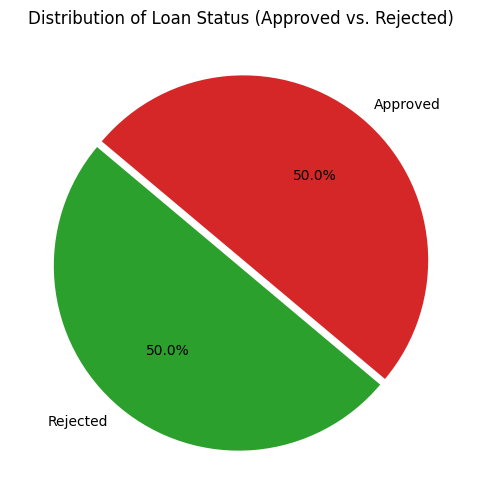

In [16]:
import matplotlib.pyplot as plt

# Calculate counts of Approved vs Rejected
status_counts = df_loans['Loan_Status'].value_counts()

# Create a pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#2ca02c', '#d62728'],
    explode=(0.02, 0.02)
)
plt.title('Distribution of Loan Status (Approved vs. Rejected)')
plt.show()

Test Accuracy: 0.9750

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.97      0.98      0.98       100
    Approved       0.98      0.97      0.97       100

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200



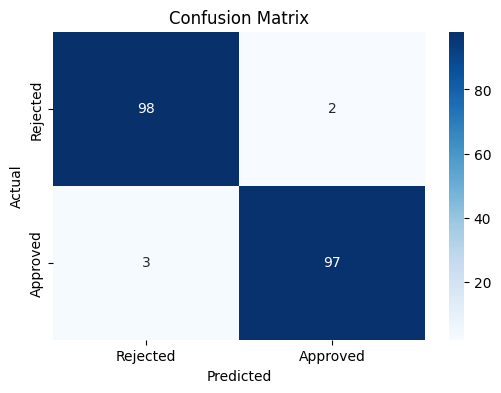

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare features and target variable
# We drop 'Loan_ID' as it's just an identifier, and 'Loan_Status' which is our target
X = df_loans.drop(columns=['Loan_ID', 'Loan_Status'])
y = df_loans['Loan_Status'].map({'Approved': 1, 'Rejected': 0}) # Encode target to 1s and 0s

# 2. Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Initialize and fit Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Predict on test set
y_pred = model.predict(X_test_scaled)

# 6. Evaluation
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Rejected', 'Approved'], yticklabels=['Rejected', 'Approved'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [13]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import pandas as pd

# Create input widgets
age_widget = widgets.IntSlider(value=35, min=21, max=100, step=1, description='Age:')
income_widget = widgets.IntText(value=60000, description='Income ($):')
loan_amount_widget = widgets.IntText(value=150000, description='Loan Amt ($):')
credit_score_widget = widgets.IntSlider(value=650, min=300, max=850, step=1, description='Credit Score:')
dti_widget = widgets.FloatSlider(value=0.35, min=0.0, max=1.0, step=0.01, description='DTI Ratio:')

predict_button = widgets.Button(description='Predict Loan Status', button_style='success')
output_area = widgets.Output()

def make_prediction(b):
    with output_area:
        clear_output()

        # Collect input data into a DataFrame with exact features used in training
        input_data = pd.DataFrame([{
            'Age': age_widget.value,
            'Income': income_widget.value,
            'Loan_Amount': loan_amount_widget.value,
            'Credit_Score': credit_score_widget.value,
            'Debt_to_Income_Ratio': dti_widget.value
        }])

        # Scale input data
        input_scaled = scaler.transform(input_data)

        # Predict class and probability
        prediction = model.predict(input_scaled)[0]
        probability = model.predict_proba(input_scaled)[0][1]

        # Map prediction back to label
        status = "Approved" if prediction == 1 else "Rejected"
        color = "green" if prediction == 1 else "red"

        print("--- Prediction Result ---")
        print(f"Approval Probability: {probability * 100:.2f}%")
        print(f"Predicted Status: {status}")

predict_button.on_click(make_prediction)

# Display the form
input_form = widgets.VBox([
    widgets.HTML(value="<h3>Enter Custom Data to Test Model:</h3>"),
    age_widget,
    income_widget,
    loan_amount_widget,
    credit_score_widget,
    dti_widget,
    predict_button,
    output_area
])

display(input_form)

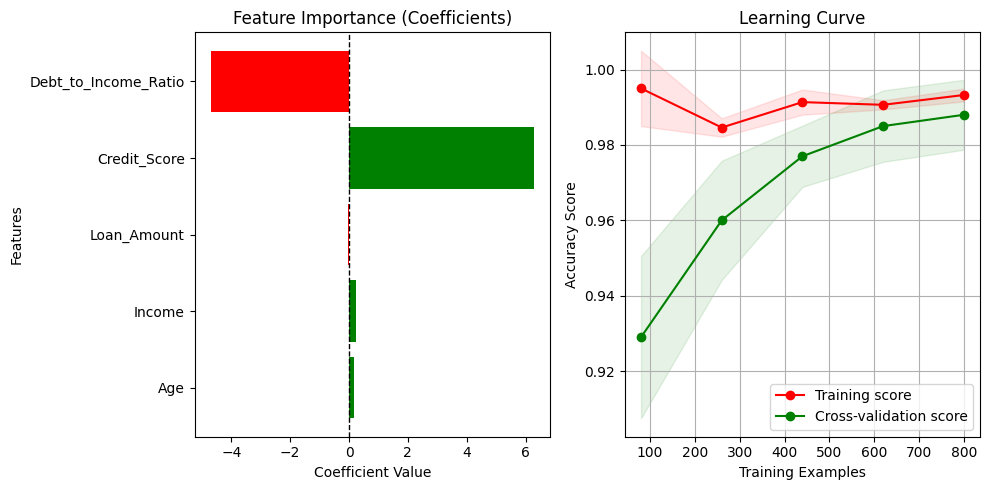

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# --- 1. Plot Feature Importance (Coefficients) ---
features = X.columns
coefficients = model.coef_[0]

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
colors = ['red' if c < 0 else 'green' for c in coefficients]
plt.barh(features, coefficients, color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Feature Importance (Coefficients)')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')

# --- 2. Calculate and Plot Learning Curve (Bias/Variance analysis) ---
# Standardize entire X for learning curve cleanly
X_scaled_all = scaler.transform(X)

train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(random_state=42),
    X_scaled_all,
    y,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 5),
    random_state=42
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.subplot(1, 2, 2)
plt.plot(train_sizes, train_mean, 'o-', color="r", label="Training score")
plt.plot(train_sizes, test_mean, 'o-', color="g", label="Cross-validation score")

plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.1, color="g")

plt.title("Learning Curve")
plt.xlabel("Training Examples")
plt.ylabel("Accuracy Score")
plt.legend(loc="best")
plt.grid(True)

plt.tight_layout()
plt.show()